x 的形状: torch.Size([100, 1])
y 的形状: torch.Size([100, 1])
前5个样本点:
 x: tensor([0.0000, 0.1010, 0.2020, 0.3030, 0.4040])
 y: tensor([1.9635, 1.9457, 1.8544, 0.5533, 2.1473])
初始 w: 0.0000, 初始 b: 0.0000
Epoch [100/1000], Loss: 0.290928, w: 2.0636, b: 0.6021
Epoch [200/1000], Loss: 0.259282, w: 2.0375, b: 0.7756
Epoch [300/1000], Loss: 0.247584, w: 2.0216, b: 0.8811
Epoch [400/1000], Loss: 0.243261, w: 2.0120, b: 0.9452
Epoch [500/1000], Loss: 0.241663, w: 2.0061, b: 0.9842
Epoch [600/1000], Loss: 0.241072, w: 2.0026, b: 1.0079
Epoch [700/1000], Loss: 0.240854, w: 2.0004, b: 1.0223
Epoch [800/1000], Loss: 0.240773, w: 1.9991, b: 1.0310
Epoch [900/1000], Loss: 0.240743, w: 1.9983, b: 1.0364
Epoch [1000/1000], Loss: 0.240732, w: 1.9978, b: 1.0396

===== 训练完成 =====
真实的 w: 2.0, 学习到的 w: 1.9978
真实的 b: 1.0, 学习到的 b: 1.0396


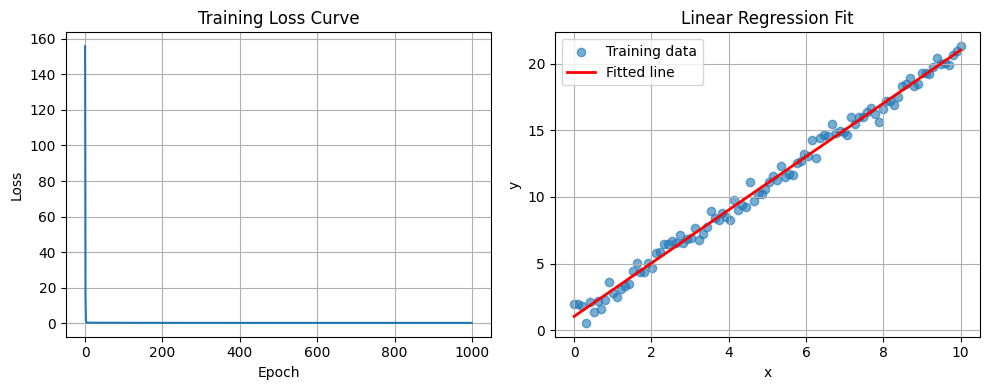

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# 设置随机种子，保证结果可复现
torch.manual_seed(42)

# 生成100个样本点，真实关系为 y = 2x + 1 + 噪声
def generate_data(n_samples=100):
    # 生成 x，范围在 [0, 10] 之间
    x = torch.linspace(0, 10, n_samples).reshape(-1, 1) #-1为占位符，自动计算维度大小。第二维大小为1，变为了二维列向量
    # 真实的权重和偏置
    w_true = 2.0
    b_true = 1.0
    # 生成 y，加上高斯噪声-->模拟真实场景
    noise = torch.randn(n_samples, 1) * 0.5
    y = w_true * x + b_true + noise
    return x, y

x_data, y_data = generate_data()

print(f"x 的形状: {x_data.shape}")
print(f"y 的形状: {y_data.shape}")
print(f"前5个样本点:\n x: {x_data[:5].flatten()}\n y: {y_data[:5].flatten()}")

# TODO: 初始化参数 w 和 b
# 提示：使用 torch.tensor 创建张量

# 初始化权重 w，形状为 (1, 1)，初始值为 0
w = torch.zeros(1, 1)
# 初始化偏置 b，形状为 (1,)，初始值为 0
b = torch.zeros(1)
print(f"初始 w: {w.item():.4f}, 初始 b: {b.item():.4f}")

# TODO: 定义线性回归模型的前向计算
def linear_model(x, w, b):
    """
    线性回归模型: y = w * x + b

    参数:
        x: 输入数据，形状为 (n_samples, 1)
        w: 权重，形状为 (1, 1)
        b: 偏置，形状为 (1,)

    返回:
        预测值，形状为 (n_samples, 1)
    """
    return w * x + b

# TODO: 定义均方误差损失函数
def mse_loss(y_pred, y_true):
    """
    均方误差损失函数: L = (1/n) * Σ(y_pred - y_true)²

    参数:
        y_pred: 预测值，形状为 (n_samples, 1)
        y_true: 真实值，形状为 (n_samples, 1)

    返回:
        损失值，一个标量
    """
    return torch.mean((y_pred - y_true) ** 2)#求全局平均值

# TODO: 手动计算损失函数对 w 和 b 的梯度
def compute_gradients(x, y_true, y_pred):
    """
    计算损失函数对 w 和 b 的梯度。
    注意：这里我们不使用 PyTorch 的自动求导，而是手动实现梯度计算。

    提示：
        - 均方误差 L = (1/n) * Σ(y_pred - y_true)²
        - ∂L/∂w = (2/n) * Σ[(y_pred - y_true) * x]
        - ∂L/∂b = (2/n) * Σ[(y_pred - y_true)]

    参数:
        x: 输入数据，形状为 (n_samples, 1)
        y_true: 真实值，形状为 (n_samples, 1)
        y_pred: 预测值，形状为 (n_samples, 1)

    返回:
        grad_w: 损失函数对 w 的梯度
        grad_b: 损失函数对 b 的梯度
    """
    n = x.shape[0]  # 样本数量

    # 计算预测值与真实值的差值
    diff = y_pred-y_true
    # 计算梯度（注意形状匹配）
    grad_w = (2/n)*torch.sum(diff*x)
    grad_b = (2/n)*torch.sum(diff)
    #相加完之后变为标量

    return grad_w, grad_b

# TODO: 实现梯度下降的参数更新
def update_parameters(w, b, grad_w, grad_b, learning_rate):
    """
    使用梯度下降更新参数
    w_new = w - lr * grad_w
    b_new = b - lr * grad_b

    参数:
        w: 当前权重
        b: 当前偏置
        grad_w: w 的梯度
        grad_b: b 的梯度
        learning_rate: 学习率

    返回:
        更新后的 w 和 b
    """
    w_new = w-learning_rate*grad_w
    b_new = b-learning_rate*grad_b
    return w_new, b_new

# TODO: 补全训练循环
def train(x, y, w, b, learning_rate, num_epochs):
    """
    训练线性回归模型

    参数:
        x: 训练数据
        y: 目标值
        w: 初始权重
        b: 初始偏置
        learning_rate: 学习率
        num_epochs: 训练轮数

    返回:
        训练过程中的损失记录, 训练好的 w 和 b
    """
    losses = []#初始化空列表

    for epoch in range(num_epochs):
        # 1. 前向传播：计算预测值
        y_pred = linear_model(x, w, b)
        # 2. 计算损失
        loss = mse_loss(y_pred, y)
        losses.append(loss.item())
        #里层：将只包含单个数值的张量转换为浮点数
        #外层：将元素追加到列表末尾

        # 3. 计算梯度
        grad_w, grad_b = compute_gradients(x, y, y_pred)
        # 4. 更新参数
        w, b = update_parameters(w, b, grad_w, grad_b, learning_rate)
        # 5. 每100轮打印一次损失
        if (epoch + 1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.6f}, w: {w.item():.4f}, b: {b.item():.4f}')

    return losses, w, b

# 设置超参数
learning_rate = 0.01
num_epochs = 1000

# 开始训练
losses, w_trained, b_trained = train(x_data, y_data, w, b, learning_rate, num_epochs)

print("\n===== 训练完成 =====")
print(f"真实的 w: 2.0, 学习到的 w: {w_trained.item():.4f}")
print(f"真实的 b: 1.0, 学习到的 b: {b_trained.item():.4f}")

# 绘制损失下降曲线
plt.figure(figsize=(10, 4))#创建宽10英尺，高4英尺的画布

plt.subplot(1, 2, 1)#将画布切分成一行两列的子图，最后的1表示现在要画左边第一个图
plt.plot(losses)#losses列表连成线
plt.xlabel('Epoch')#设置横坐标
plt.ylabel('Loss')#设置纵坐标
plt.title('Training Loss Curve')#设置标题
plt.grid(True)#打开背景表格

# 绘制拟合结果
plt.subplot(1, 2, 2)#切换到第二个子图
#画散点图，aipha为透明度，label为点的名字
#.numpy会将张量转换为普通数组
plt.scatter(x_data.numpy(), y_data.numpy(), alpha=0.6, label='Training data')
#根据权重画预测直线
plt.plot(x_data.numpy(), (w_trained * x_data + b_trained).numpy(),
         color='red', linewidth=2, label='Fitted line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Linear Regression Fit')
plt.legend()#自动生成图例
plt.grid(True)

plt.tight_layout()#自动调整子图间距
plt.savefig('./images/linear_regression_manual_result.png', dpi=150)#保存路径
plt.show()#在屏幕终端显示

In [ ]:
#导入库
import torch
import torch.nn as nn
import torch.optim as optim
import matplotilb.pyplot as plt
import numpy as np
import os

#使用了两个库生成随机数所以需要设置两个种子，上一题没有用numpy生成随机数所以不需要
torch.manualseed(42)
np.random.seed(42)

# ==========================================
# 1. 生成训练数据集
# ==========================================
def generate_data(n_samples=100):
    #二元回归中均匀生成会导致x1和x2一样
    #直接生成了（100，1）的张量，不需要reshape
    x1=torch.rand(n_samples, 1)*10
    x1=torch.rand(n_samples, 1)*10


SyntaxError: incomplete input (712114583.py, line 16)